# import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/raw/Telco-Customer-Churn.csv")

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Investigating those with `NaN` TotalCharges
blank = df[df['TotalCharges'].isna()]
print(blank[['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']])
print(f"Rows with NaN TotalCharges: {len(blank)}, all with tenure==0: {(blank['tenure']==0).all()}")

# New customers have 0 total charges
df['TotalCharges'] = df['TotalCharges'].fillna(0)

      tenure  MonthlyCharges  TotalCharges Churn
488        0           52.55           NaN    No
753        0           20.25           NaN    No
936        0           80.85           NaN    No
1082       0           25.75           NaN    No
1340       0           56.05           NaN    No
3331       0           19.85           NaN    No
3826       0           25.35           NaN    No
4380       0           20.00           NaN    No
5218       0           19.70           NaN    No
6670       0           73.35           NaN    No
6754       0           61.90           NaN    No
Rows with NaN TotalCharges: 11, all with tenure==0: True


In [7]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
df.shape

(7043, 21)

## Univariate

#### Numerical Variable

In [9]:
numeric_col = df.select_dtypes(include=['int64', 'float'])
numeric_col.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


In [10]:
df['SeniorCitizen'].value_counts()

SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

In [11]:
monthly_charge_range = df['MonthlyCharges'].max() - df['MonthlyCharges'].min()
monthly_charge_range

np.float64(100.5)

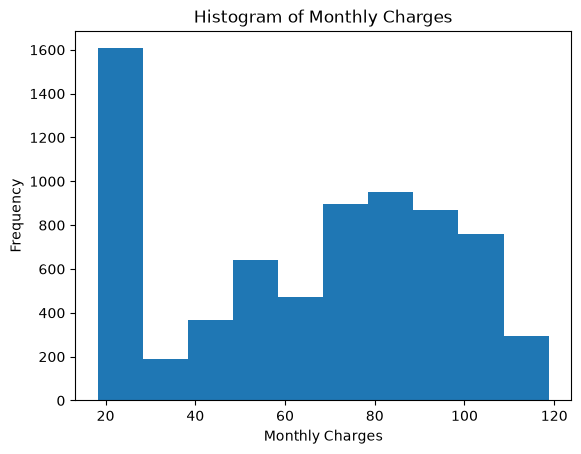

In [12]:
df['MonthlyCharges'].plot(kind='hist')
plt.xlabel('Monthly Charges')
plt.ylabel('Frequency')
plt.title('Histogram of Monthly Charges')
plt.show()

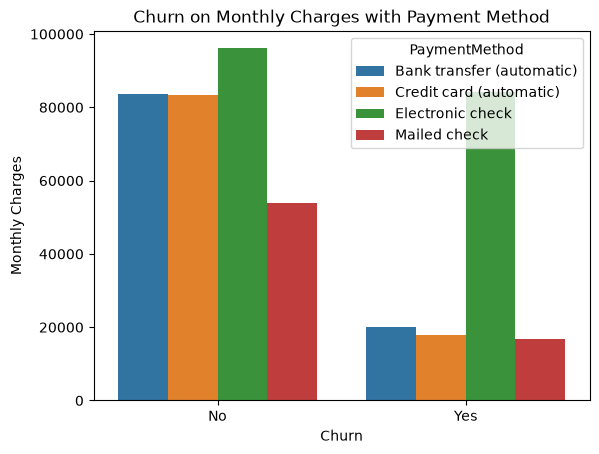

In [13]:
monthly_charges = (
    df.groupby(['Churn', 'PaymentMethod'])['MonthlyCharges']
        .sum()
        .reset_index(name='Total'
))
sns.barplot(data=monthly_charges, x="Churn", y="Total", hue="PaymentMethod")
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')
plt.title("Churn on Monthly Charges with Payment Method")
plt.show()

   Churn              PaymentMethod InternetService     Total
0     No  Bank transfer (automatic)             DSL  32669.80
1     No  Bank transfer (automatic)     Fiber optic  44208.95
2     No  Bank transfer (automatic)              No   6774.80
3     No    Credit card (automatic)             DSL  33455.90
4     No    Credit card (automatic)     Fiber optic  42939.00
5     No    Credit card (automatic)              No   6890.35
6     No           Electronic check             DSL  25062.95
7     No           Electronic check     Fiber optic  68700.05
8     No           Electronic check              No   2293.25
9     No               Mailed check             DSL  26947.50
10    No               Mailed check     Fiber optic  13136.35
11    No               Mailed check              No  13906.85
12   Yes  Bank transfer (automatic)             DSL   2733.55
13   Yes  Bank transfer (automatic)     Fiber optic  16986.60
14   Yes  Bank transfer (automatic)              No    371.75
15   Yes

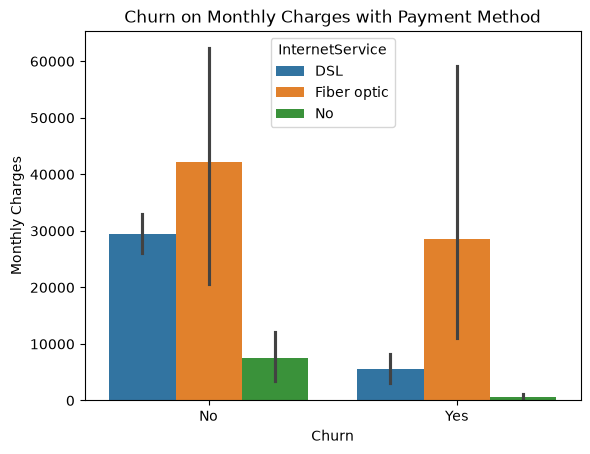

In [14]:
monthly_charges_internet_service = (
    df.groupby(['Churn', 'PaymentMethod', 'InternetService'])['MonthlyCharges']
        .sum()
        .reset_index(name='Total'
))
print(monthly_charges_internet_service)
sns.barplot(data=monthly_charges_internet_service, x="Churn", y="Total", hue="InternetService")
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')
plt.title("Churn on Monthly Charges with Payment Method")
plt.show()

From the above, it shows that Electronic check as a payment method, contribute the most to the churning of the customers, which was as a result of the higher charges that is apply on it. 
And more applicable to customers using fiber optic.

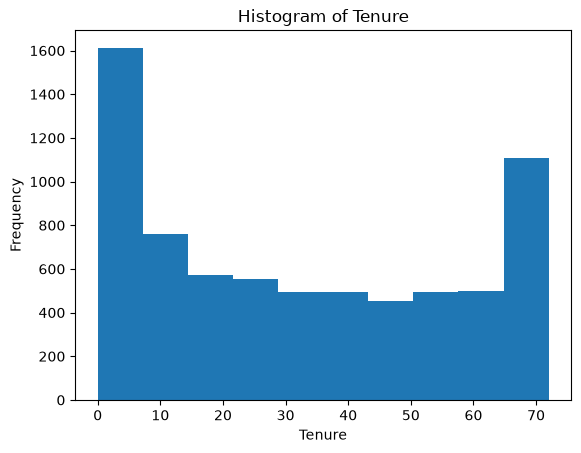

In [15]:
df['tenure'].plot(kind='hist')
plt.xlabel('Tenure')
plt.ylabel('Frequency')
plt.title('Histogram of Tenure')
plt.show()

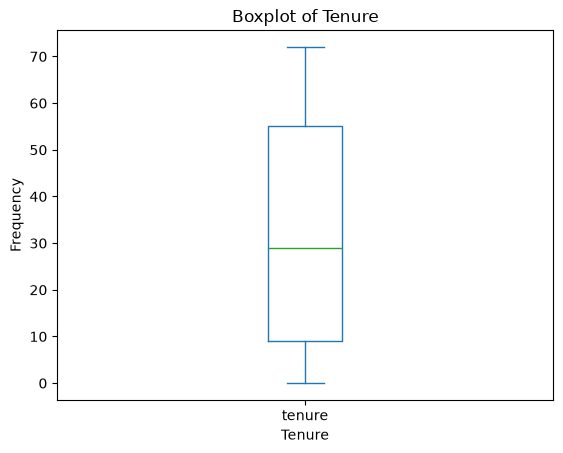

In [16]:
df['tenure'].plot(kind='box')
plt.xlabel('Tenure')
plt.ylabel('Frequency')
plt.title('Boxplot of Tenure')
plt.show()

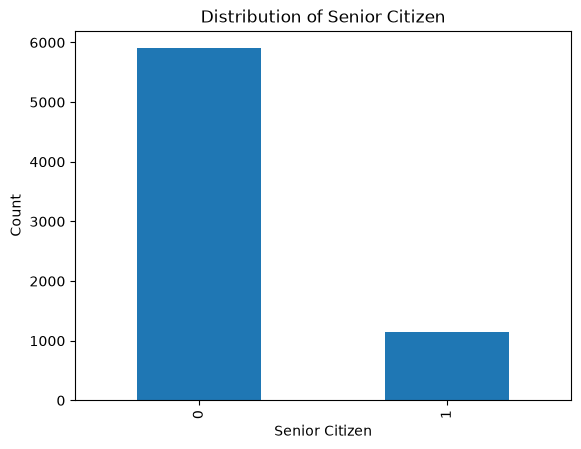

In [17]:
df['SeniorCitizen'].value_counts().plot(kind='bar')
plt.xlabel('Senior Citizen')
plt.ylabel('Count')
plt.title('Distribution of Senior Citizen')
plt.show()

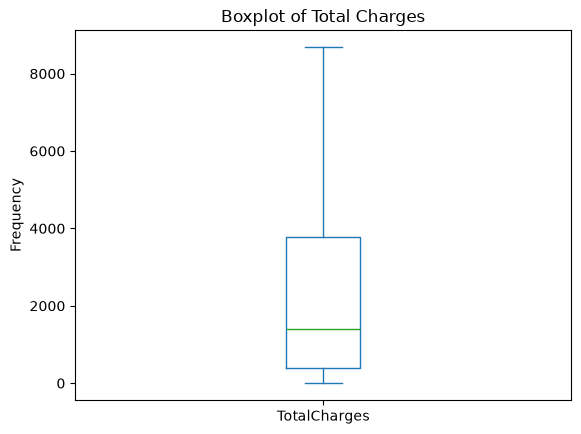

In [18]:
df['TotalCharges'].plot(kind='box')
plt.ylabel('Frequency')
plt.title('Boxplot of Total Charges')
plt.show()

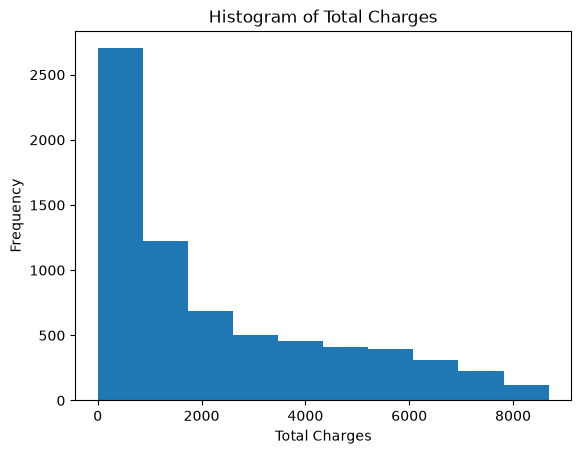

In [19]:
df['TotalCharges'].plot(kind='hist')
plt.xlabel('Total Charges')
plt.ylabel('Frequency')
plt.title('Histogram of Total Charges')
plt.show()

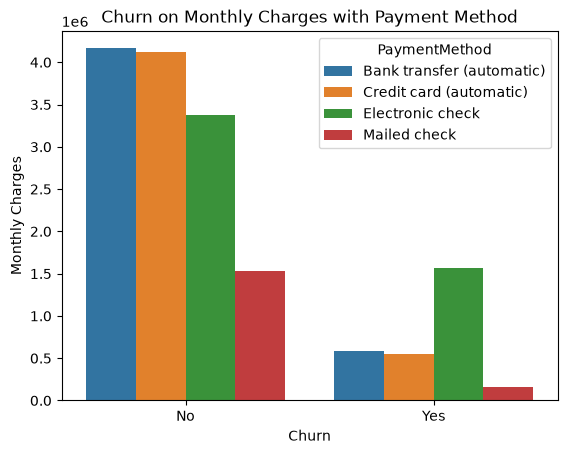

In [20]:
total_charges =(
    df.groupby(['Churn', 'PaymentMethod'])['TotalCharges']
        .sum()
        .reset_index(name='Total')
)
sns.barplot(data=total_charges, x="Churn", y="Total", hue="PaymentMethod")
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')
plt.title("Churn on Monthly Charges with Payment Method")
plt.show()

In [21]:
df['TotalCharges'].min()

np.float64(0.0)

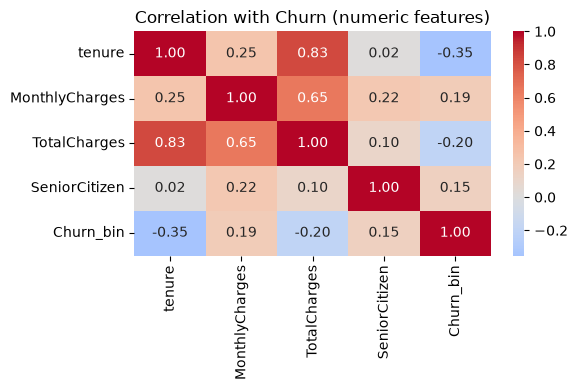

In [22]:
import seaborn as sns
num_df = df[['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']].copy()
num_df['Churn_bin'] = (df['Churn'] == 'Yes').astype(int)

plt.figure(figsize=(6, 4))
sns.heatmap(num_df.corr(), annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Correlation with Churn (numeric features)')
plt.tight_layout()
plt.show()

### Correlation with Churn (Numeric Features)

    - Tenure (-0.35 correlation) — Shows a moderate negative correlation with churn, indicating that longer-tenured customers are significantly less likely to churn.   

    - Monthly Charges (+0.19 correlation) — Exhibits a weak-to-moderate positive correlation with churn, showing that customers with higher monthly bills churn at higher rates.   

    - Total Charges (-0.20 correlation) — Has a weak negative correlation with churn, largely driven by its strong association with tenure.   

    - Senior Citizen Status (+0.15 correlation) — Shows a slight positive correlation with churn, indicating that senior citizens have a marginally higher propensity to churn compared to non-seniors.

In [23]:
df['tenure_bin'] = pd.cut(df['tenure'], bins=[0, 6, 12, 24, 48, 72],
                          labels=['0-6', '6-12', '12-24', '24-48', '48-72'])
print((df.groupby('tenure_bin', observed=True)['Churn']
         .apply(lambda s: (s=='Yes').mean()*100).round(2)))

tenure_bin
0-6      53.33
6-12     35.89
12-24    28.71
24-48    20.39
48-72     9.51
Name: Churn, dtype: float64


Newly admitted customers 6 - 12years are at higher risk to churn, and customers that are long-termed are slightly less to churn

#### Categorical Variables

In [24]:
categorical_col = df.select_dtypes('str')
categorical_col.head()

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
0,7590-VHVEG,Female,Yes,No,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,No
1,5575-GNVDE,Male,No,No,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,No
2,3668-QPYBK,Male,No,No,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,Yes
3,7795-CFOCW,Male,No,No,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),No
4,9237-HQITU,Female,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,Yes


In [25]:
for col in categorical_col.columns.tolist():
    print(f"Column {col} has: {df[col].nunique()}")

Column customerID has: 7043
Column gender has: 2
Column Partner has: 2
Column Dependents has: 2
Column PhoneService has: 2
Column MultipleLines has: 3
Column InternetService has: 3
Column OnlineSecurity has: 3
Column OnlineBackup has: 3
Column DeviceProtection has: 3
Column TechSupport has: 3
Column StreamingTV has: 3
Column StreamingMovies has: 3
Column Contract has: 3
Column PaperlessBilling has: 2
Column PaymentMethod has: 4
Column Churn has: 2


In [26]:
def plotBar(categorical_col):
    for col in categorical_col.columns:
        plt.figure(figsize=(8, 4))
        sns.countplot(data=categorical_col, x=col, hue='Churn', stat='count')
        
        # Formatting for better readability
        plt.title(f'Bar Plot of {col}', fontsize=12)
        plt.xlabel(col, fontsize=10)
        plt.ylabel('Count', fontsize=10)
        plt.xticks(rotation=45, ha='right') # Rotates labels if they are long
        
        plt.tight_layout()
        plt.show()

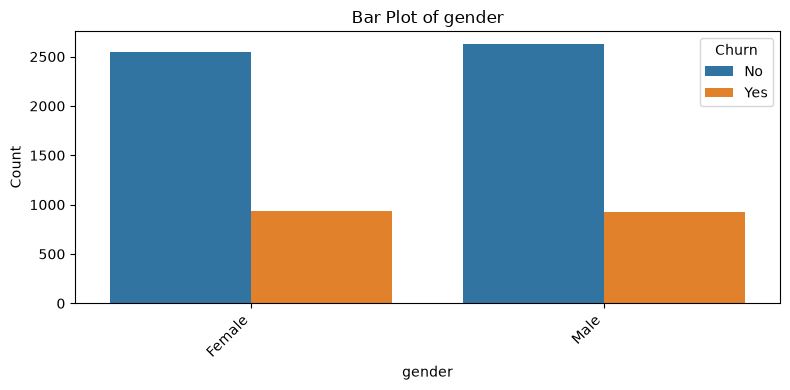

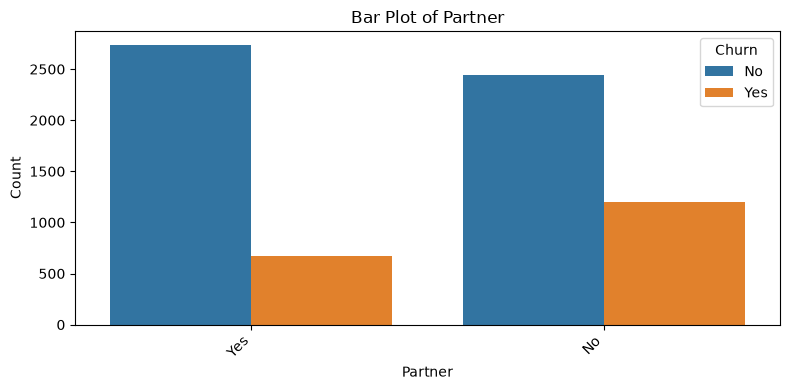

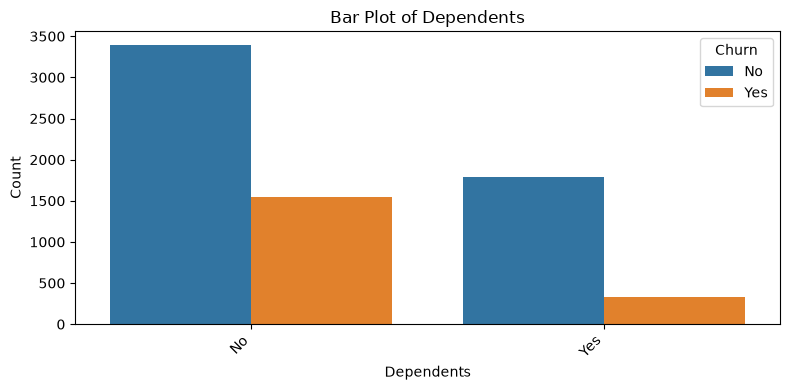

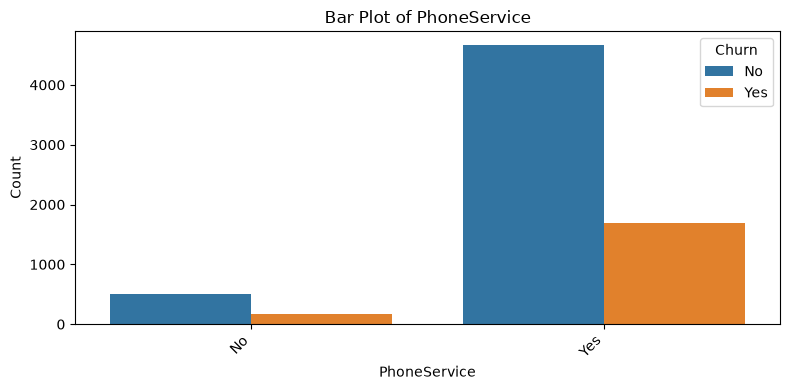

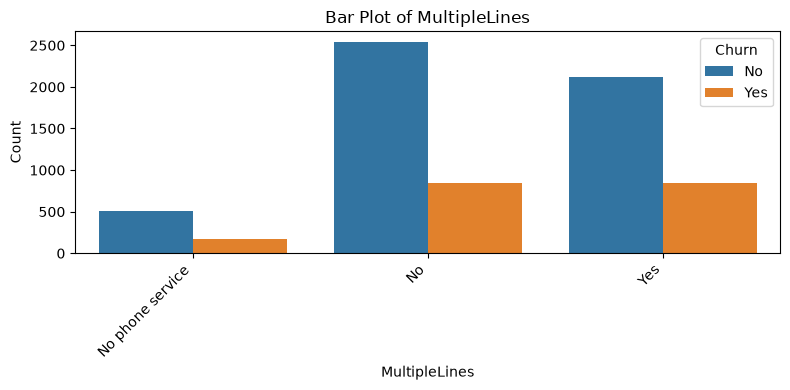

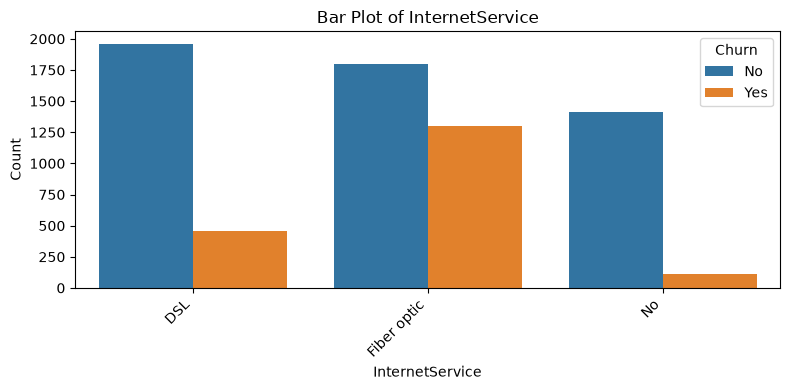

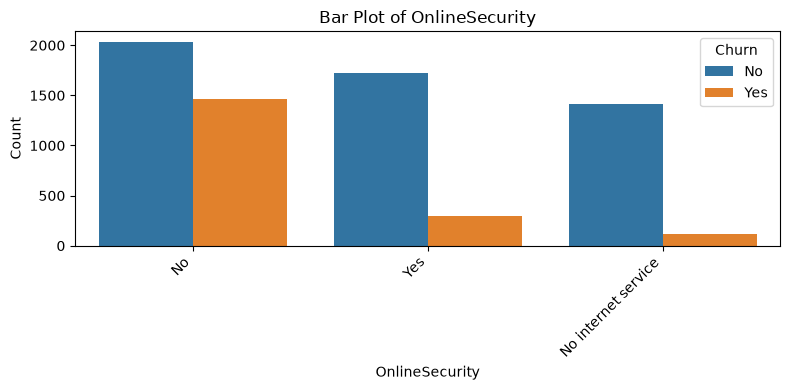

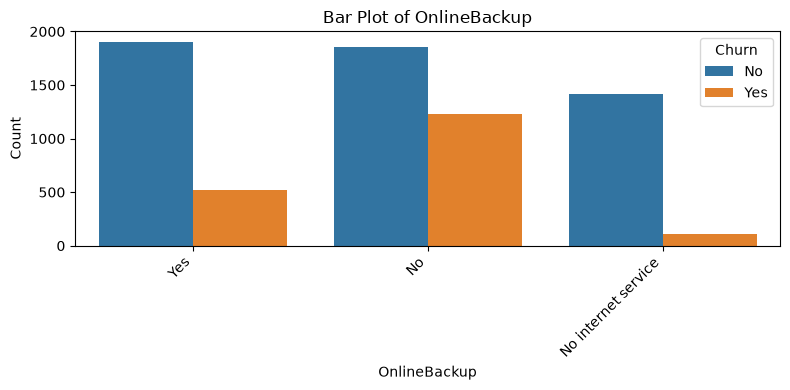

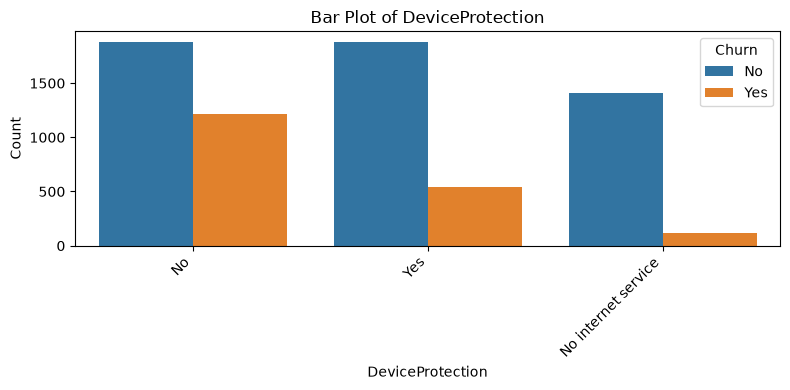

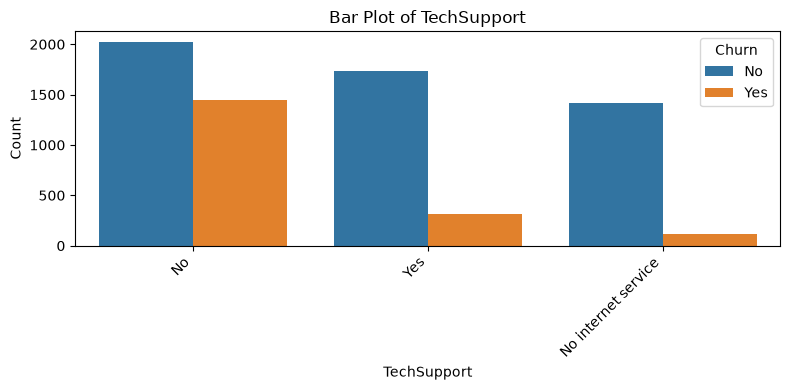

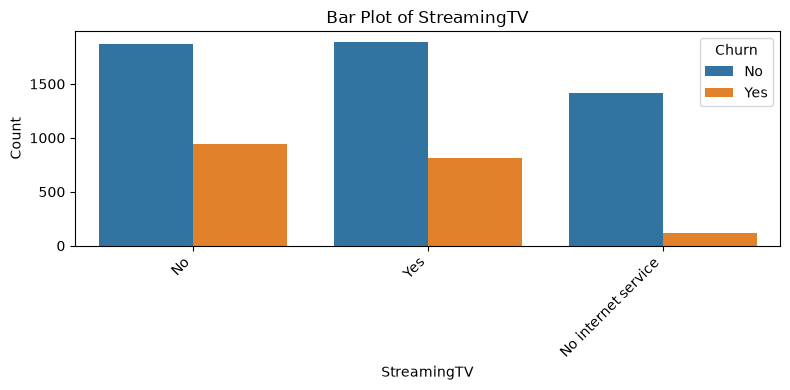

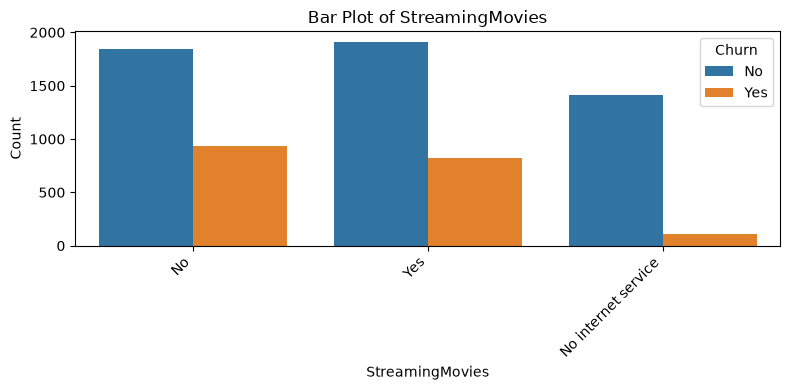

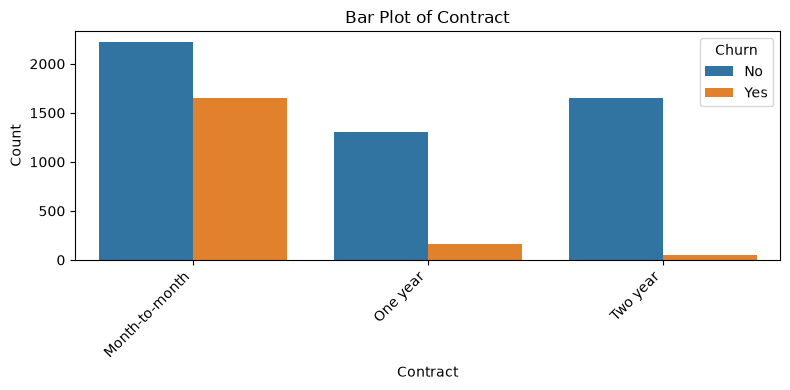

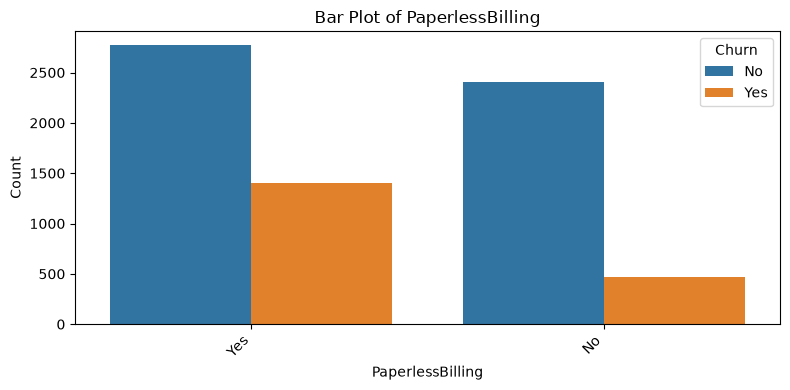

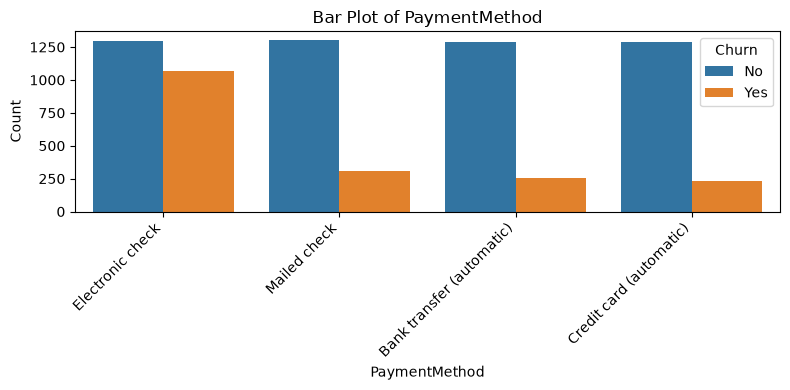

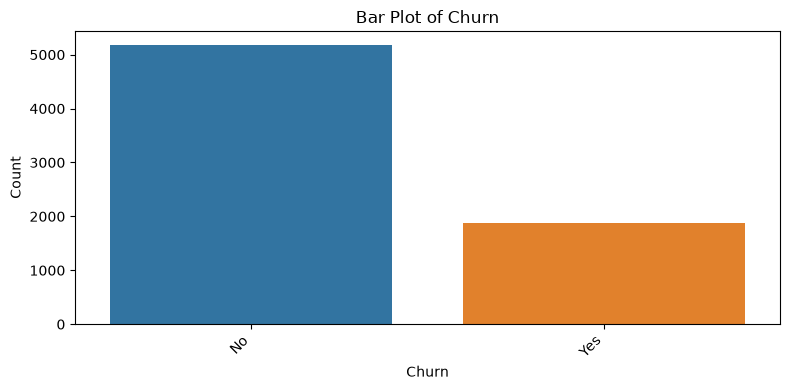

In [27]:
plotBar(categorical_col.drop(columns=['customerID']))

In [28]:
for col in categorical_col.columns[1:]:
    print(f'============= col =============')
    print(df[col].value_counts())
    print(f'===========================')

============= col =============
gender
Male      3555
Female    3488
Name: count, dtype: int64
============= col =============
Partner
No     3641
Yes    3402
Name: count, dtype: int64
============= col =============
Dependents
No     4933
Yes    2110
Name: count, dtype: int64
============= col =============
PhoneService
Yes    6361
No      682
Name: count, dtype: int64
============= col =============
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64
============= col =============
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64
============= col =============
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64
============= col =============
OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64
============= col =============
De

In [29]:
for col in categorical_col.columns[1:]:
    print(f'============= col =============')
    print(round(df[col].value_counts(normalize=True)*100, 2))
    print(f'===========================')

============= col =============
gender
Male      50.48
Female    49.52
Name: proportion, dtype: float64
============= col =============
Partner
No     51.7
Yes    48.3
Name: proportion, dtype: float64
============= col =============
Dependents
No     70.04
Yes    29.96
Name: proportion, dtype: float64
============= col =============
PhoneService
Yes    90.32
No      9.68
Name: proportion, dtype: float64
============= col =============
MultipleLines
No                  48.13
Yes                 42.18
No phone service     9.68
Name: proportion, dtype: float64
============= col =============
InternetService
Fiber optic    43.96
DSL            34.37
No             21.67
Name: proportion, dtype: float64
============= col =============
OnlineSecurity
No                     49.67
Yes                    28.67
No internet service    21.67
Name: proportion, dtype: float64
============= col =============
OnlineBackup
No                     43.84
Yes                    34.49
No internet service   

In [30]:
cols = categorical_col.columns.tolist()[1:-1]
for col in cols:
    print(f"==========Cross Tabulation of {col}==========")
    print(pd.crosstab(df['Churn'], df[col]))

==========Cross Tabulation of gender==========
gender  Female  Male
Churn               
No        2549  2625
Yes        939   930
==========Cross Tabulation of Partner==========
Partner    No   Yes
Churn              
No       2441  2733
Yes      1200   669
==========Cross Tabulation of Dependents==========
Dependents    No   Yes
Churn                 
No          3390  1784
Yes         1543   326
==========Cross Tabulation of PhoneService==========
PhoneService   No   Yes
Churn                  
No            512  4662
Yes           170  1699
==========Cross Tabulation of MultipleLines==========
MultipleLines    No  No phone service   Yes
Churn                                      
No             2541               512  2121
Yes             849               170   850
==========Cross Tabulation of InternetService==========
InternetService   DSL  Fiber optic    No
Churn                                   
No               1962         1799  1413
Yes               459         1297   113

In [31]:
# Add this cell after your crosstab cell
for col in ['Contract', 'PaymentMethod', 'InternetService',
            'OnlineSecurity', 'TechSupport', 'PaperlessBilling']:
    rate = (df.groupby(col)['Churn']
              .apply(lambda s: (s == 'Yes').mean() * 100)
              .round(2)
              .sort_values(ascending=False))
    print(f"\n=== Churn rate (%) by {col} ===")
    print(rate)


=== Churn rate (%) by Contract ===
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

=== Churn rate (%) by PaymentMethod ===
PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn, dtype: float64

=== Churn rate (%) by InternetService ===
InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn, dtype: float64

=== Churn rate (%) by OnlineSecurity ===
OnlineSecurity
No                     41.77
Yes                    14.61
No internet service     7.40
Name: Churn, dtype: float64

=== Churn rate (%) by TechSupport ===
TechSupport
No                     41.64
Yes                    15.17
No internet service     7.40
Name: Churn, dtype: float64

=== Churn rate (%) by PaperlessBilling ===
PaperlessBilling
Yes    33.57
No     16.33
Name: Churn, dtype: float64


## FIndings

### Contract Type
    - Month-to-month customers churn at 43% — nearly 4x the rate of one-year contracts and roughly 15x the rate of two-year contracts.
    - One-year contract customers churn at 11% — about 4x the rate of two-year contract customers.
    - Two-year contract customers churn at 3% — representing the highest customer retention across contract lengths.

### Payment Method
    - Electronic check customers churn at 45% — roughly 3x the rate of automatic payment methods (bank transfer and credit card).
    - Mailed check customers churn at 19% — slightly higher than automatic payment methods.
    - Bank transfer (automatic) customers churn at 17% — closely aligned with credit card automatic payments.
    - Credit card (automatic) customers churn at 15% — matching bank transfers as the most stable payment channels.

### Internet Service
    - Fiber optic customers churn at 42% — more than 2x the rate of DSL users and nearly 6x the rate of customers with no internet service.
    - DSL customers churn at 19% — roughly half the churn rate of fiber optic users.
    - Customers with no internet service churn at 7% — the lowest churn category for connectivity options.

### Online Security
    - Customers without online security churn at 42% — nearly 3x the rate of customers who have the service enabled.
    - Customers with online security churn at 15% — showing significantly higher retention than unprotected accounts.
    - Customers with no internet service churn at 7% — maintaining the baseline low churn seen across non-internet features.

### Tech Support
    - Customers without tech support churn at 42% — nearly 3x the rate of customers who have access to technical support.
    - Customers with tech support churn at 15% — indicating strong correlation between technical assistance and retention.
    - Customers with no internet service churn at 7% — consistent with other non-internet baseline groups.

### Paperless Billing
    - Paperless billing customers churn at 34% — more than double the rate of customers who receive traditional paper bills.
    - Non-paperless billing customers churn at 16% — showing much higher loyalty than those on paperless options.